In [1]:
# ── 셀 1 │ 설정 ──
import os, sys, json, time, random, urllib.request, urllib.parse
import numpy as np, pandas as pd, torch
import torch.nn as nn, torch.nn.functional as F
from torch_geometric.data import Data
from torch_geometric.loader import DataLoader
from torch_geometric.utils import add_self_loops, softmax
from sklearn.metrics import (roc_auc_score, average_precision_score,
                             accuracy_score, f1_score,
                             precision_score, recall_score)
from sklearn.model_selection import train_test_split
from rdkit import Chem, RDLogger
from rdkit.Chem.Scaffolds import MurckoScaffold
RDLogger.DisableLog('rdApp.*')

NEW  = r'C:\Users\iisl\Desktop\0_Molecualar_Informatics\2026_final\2026_new' + '\\'
CLIN = NEW + r'data\processed\clinical\clinical_pool_endpoints.csv'
CMP  = NEW + r'data\processed\crediblemeds\crediblemeds_pool.csv'
IK   = NEW + r'data\processed\crediblemeds\name2key_cache.json'
SMIC = NEW + r'data\processed\crediblemeds\crediblemeds_smiles.csv'
CKPT = NEW + r'03_dedup\pretrain_drop.pt'      # None 이면 clinical-only
RES  = NEW + r'results\external\\'
os.makedirs(RES, exist_ok=True)
for p in [CLIN, CMP]:
    assert os.path.exists(p), p

sys.path.insert(0, NEW + '01_pre-train')
import featurizer as FZ

DEV   = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
SEEDS = (42, 43, 44)
FT_LR_BB, FT_LR_CLF, FT_EPOCHS, FT_PAT, FT_BS = 1e-4, 5e-3, 60, 12, 32
HID, HEADS, DROP = 32, 8, 0.3
THR   = 0.50
print(DEV, '| atom', FZ.num_atom_features())

C:\Users\iisl\anaconda3\envs\esu_gpu\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


cuda | atom 39


In [2]:
# ── 셀 2 │ 모델 (체크포인트 로드용, 학습 때와 동일 구조) ──
class GH(nn.Module):
    def __init__(s, ic, oc, d=DROP):
        super().__init__()
        s.W = nn.Parameter(torch.empty(ic, oc)); s.a = nn.Parameter(torch.empty(2*oc, 1))
        nn.init.xavier_uniform_(s.W); nn.init.xavier_uniform_(s.a)
        s.lr = nn.LeakyReLU(0.2); s.d = d
    def forward(s, x, ei):
        ei, _ = add_self_loops(ei, num_nodes=x.size(0))
        h = x @ s.W; row, col = ei
        e = s.lr((torch.cat([h[row], h[col]], -1) @ s.a).squeeze(-1))
        e = F.dropout(e, s.d, training=s.training)
        al = softmax(e, row)
        o = torch.zeros_like(h); o.index_add_(0, row, h[col] * al.unsqueeze(-1))
        return F.elu(o)

class GL(nn.Module):
    def __init__(s, ic, oc, h, d=DROP):
        super().__init__()
        s.h, s.d = h, d
        s.att = nn.ModuleList([GH(ic, oc, d) for _ in range(h)])
    def forward(s, x, ei):
        z = (torch.mean(torch.stack([a(x, ei) for a in s.att], 0), 0) if s.h == 1
             else torch.cat([a(x, ei) for a in s.att], -1))
        return F.dropout(z, s.d, training=s.training)

class AttentionPool(nn.Module):
    def __init__(s, ch, d=DROP):
        super().__init__()
        s.gate = nn.Sequential(nn.Linear(ch, ch), nn.ReLU(), nn.Dropout(d), nn.Linear(ch, 1))
    def forward(s, x, batch):
        al = softmax(s.gate(x).squeeze(-1), batch)
        out = torch.zeros(int(batch.max()) + 1, x.size(1), device=x.device, dtype=x.dtype)
        out.index_add_(0, batch, x * al.unsqueeze(-1))
        return out

class GAT_SI(nn.Module):
    def __init__(s, ic, hc=HID, h=HEADS, d=DROP):
        super().__init__()
        s.l1 = GL(ic, hc, h, d); s.l2 = GL(hc*h, hc, h, d); s.l3 = GL(hc*h, hc, 1, d)
        s.pool = AttentionPool(hc, d)
        s.clf = nn.Sequential(nn.Linear(hc, 64), nn.ReLU(), nn.Dropout(d), nn.Linear(64, 1))
    def forward(s, x, ei, b):
        x = F.elu(s.l1(x, ei)); x = F.elu(s.l2(x, ei)); x = s.l3(x, ei)
        return s.clf(s.pool(x, b)).squeeze(-1)

@torch.no_grad()
def probs(model, ld):
    model.eval(); out = []
    for b in ld:
        b = b.to(DEV)
        out += torch.sigmoid(model(b.x, b.edge_index, b.batch)).cpu().tolist()
    return np.array(out)

def load_ft(path):
    ck = torch.load(path, map_location='cpu', weights_only=False)
    m = GAT_SI(ck['atom_dim']).to(DEV)
    m.load_state_dict({k: v.to(DEV) for k, v in ck['state_dict'].items()})
    return m, ck

In [3]:
# ── 셀 3 │ CredibleMeds SMILES ──
cm = pd.read_csv(CMP, encoding='utf-8-sig')
cm = cm.loc[:, ~cm.columns.duplicated()].drop_duplicates('key14')
print('CredibleMeds', len(cm), '| tier', dict(cm['tier'].value_counts()))

BASE  = 'https://pubchem.ncbi.nlm.nih.gov/rest/pug/compound'
PROPS = 'SMILES,ConnectivitySMILES,IsomericSMILES,CanonicalSMILES'
KEYS  = ['IsomericSMILES', 'SMILES', 'CanonicalSMILES', 'ConnectivitySMILES']

def _get(url):
    req = urllib.request.Request(url, headers={'User-Agent': 'python-urllib'})
    with urllib.request.urlopen(req, timeout=20) as r:
        return json.loads(r.read().decode())

def fetch_smiles(ik=None, name=None):
    urls = []
    if ik:   urls.append((f'{BASE}/inchikey/{ik}/property/{PROPS}/JSON', 'ik'))
    if name: urls.append((f'{BASE}/name/{urllib.parse.quote(str(name))}'
                          f'/property/{PROPS}/JSON', 'name'))
    for url, via in urls:
        try:
            p = _get(url)['PropertyTable']['Properties'][0]
        except Exception:
            continue
        for k in KEYS:
            if p.get(k):
                return p[k], via
    return None, None

if os.path.exists(SMIC):
    smi_df = pd.read_csv(SMIC, encoding='utf-8-sig')
    print('SMILES 캐시 로드', len(smi_df))
else:
    n2k = json.load(open(IK, encoding='utf-8')) if os.path.exists(IK) else {}
    ik_by_name = {k: v.get('inchikey') for k, v in n2k.items()}
    rec = []
    for i, (_, r) in enumerate(cm.iterrows()):
        ik = r.get('pubchem_ik') or ik_by_name.get(str(r.get('name_primary')))
        s, via = fetch_smiles(ik, r.get('name_primary'))
        rec.append({'key14': r['key14'], 'pubchem_ik': ik,
                    'name_primary': r.get('name_primary'),
                    'smiles': s, 'resolved_via': via})
        if (i + 1) % 25 == 0:
            print(f'{i+1}/{len(cm)}  확보 {sum(1 for x in rec if x["smiles"])}',
                  flush=True)
        time.sleep(0.25)                      # PubChem 권장 5 req/s 이하
    smi_df = pd.DataFrame(rec)
    smi_df.to_csv(SMIC, index=False, encoding='utf-8-sig')

ok = smi_df['smiles'].notna().sum()
print(f'SMILES 확보 {ok} / {len(smi_df)}')
print(smi_df['resolved_via'].value_counts(dropna=False))
assert ok > 0, 'property 이름을 다시 확인하세요'
if ok < len(smi_df):
    print('미해결:', smi_df.loc[smi_df['smiles'].isna(),
                               'name_primary'].tolist()[:20])

CredibleMeds 270 | tier {'Possible': 152, 'Known': 67, 'Conditional': 51}
SMILES 캐시 로드 270
SMILES 확보 270 / 270
resolved_via
ik    270
Name: count, dtype: int64


In [4]:
# ── 셀 4 │ 그래프 (임상 + 외부) ──
def _prep(smi):
    m = Chem.MolFromSmiles(str(smi))
    if m is None: return None
    try: Chem.SanitizeMol(m)
    except Exception: return None
    try: Chem.AssignStereochemistry(m, cleanIt=True, force=True)
    except Exception: pass
    return m

def make_graph(smi, y=None):
    mol = _prep(smi)
    if mol is None: return None
    try: x = np.stack([FZ.atom_features(a) for a in mol.GetAtoms()])
    except Exception: return None
    src, dst, ea = [], [], []
    for b in mol.GetBonds():
        i, j = b.GetBeginAtomIdx(), b.GetEndAtomIdx()
        bf = FZ.bond_features(b)
        src += [i, j]; dst += [j, i]; ea += [bf, bf]
    if not src: return None
    g = Data(x=torch.tensor(np.asarray(x, np.float32)),
             edge_index=torch.tensor([src, dst], dtype=torch.long),
             edge_attr=torch.tensor(np.asarray(ea, np.float32)))
    g.y = torch.tensor([float(y if y is not None else 1.0)], dtype=torch.float)
    return g

def scaffold_of(smi):
    try:
        return MurckoScaffold.MurckoScaffoldSmiles(smiles=str(smi),
                                                   includeChirality=False)
    except Exception:
        return ''

# ── 임상 ── CSV 행 순서를 그대로 유지해야 마스크가 맞는다
clin = pd.read_csv(CLIN, encoding='utf-8-sig')
clin['_qt_blank'] = clin['cm_qt'].isna() & clin['cm_tdp'].isna()   # ← 캐스팅 전에
for c in ['listed', 'cm_qt', 'cm_tdp']:
    if c in clin.columns:
        clin[c] = clin[c].astype(str).str.lower().isin(['true', '1'])

# scaffold 보강: 비고리 분자는 Murcko scaffold 가 빈 문자열이라 NaN 으로 읽힌다
sc = (clin['scaffold'] if 'scaffold' in clin.columns
      else pd.Series([None] * len(clin), index=clin.index))
sc = sc.astype(str).str.strip().replace({'nan': '', 'None': '', '<NA>': ''})
need = sc.str.len() == 0
if need.any():
    sc.loc[need] = clin.loc[need, 'canon_smiles'].map(scaffold_of)
    sc = sc.astype(str).str.strip()
    still = sc.str.len() == 0
    sc.loc[still] = clin.loc[still, 'canon_smiles']   # 비고리 분자는 자기 자신
    print(f'scaffold 보강 {int(need.sum())}종 (그중 비고리 {int(still.sum())}종)')
clin['scaffold'] = sc.values
assert not clin['scaffold'].astype(str).str.strip().eq('').any()

Cg, keep = [], []
for i, r in clin.iterrows():
    g = make_graph(r['canon_smiles'], r['y'])
    if g is None: continue
    Cg.append(g); keep.append(i)
M = clin.loc[keep].reset_index(drop=True)
y = M['y'].astype(int).values
print('임상', len(Cg), dict(M['y'].value_counts()),
      '| scaffold', M['scaffold'].nunique())

# ── 외부 ── 임상 풀 밖 CredibleMeds
ext = (smi_df.dropna(subset=['smiles'])
             .merge(cm[['key14', 'tier', 'QT Increase', 'TdP Cases']],
                    on='key14', how='left'))
ext = ext[~ext['key14'].isin(set(M['key14']))].drop_duplicates('key14')
print('임상 풀 밖 CredibleMeds', len(ext))

ext_g, rows = [], []
for _, r in ext.iterrows():
    g = make_graph(r['smiles'], 1.0)
    if g is None: continue
    ext_g.append(g)
    rows.append({'key14': r['key14'], 'name': r['name_primary'],
                 'tier': r['tier'], 'qt': r['QT Increase'],
                 'tdp': r['TdP Cases']})
E = pd.DataFrame(rows)
print('그래프화', len(ext_g), '/', len(ext))
print(E['tier'].value_counts())

scaffold 보강 86종 (그중 비고리 86종)
임상 1225 {1: 725, 0: 500} | scaffold 921
임상 풀 밖 CredibleMeds 127
그래프화 124 / 127
tier
Possible       80
Known          26
Conditional    18
Name: count, dtype: int64


In [5]:
# ── 셀 5 │ 지표 / 학습 루프 / fold ──
def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    torch.cuda.manual_seed_all(s)

def metrics(yt, p, thr=0.5):
    yh = (np.asarray(p) >= thr).astype(int); yt = np.asarray(yt).astype(int)
    return dict(accuracy=accuracy_score(yt, yh),
                auroc=roc_auc_score(yt, p) if len(set(yt)) > 1 else np.nan,
                aucpr=average_precision_score(yt, p) if len(set(yt)) > 1 else np.nan,
                f1=f1_score(yt, yh, zero_division=0),
                precision=precision_score(yt, yh, zero_division=0),
                recall=recall_score(yt, yh, zero_division=0))

@torch.no_grad()
def predict(model, loader):
    model.eval(); ps, ys = [], []
    for b in loader:
        b = b.to(DEV)
        ps += torch.sigmoid(model(b.x, b.edge_index, b.batch)).cpu().tolist()
        ys += b.y.view(-1).cpu().tolist()
    return np.array(ys), np.array(ps)

def fit(model, tr_ds, va_ds, opt, epochs, patience, bsz):
    tr = DataLoader(tr_ds, batch_size=bsz, shuffle=True)
    vl = DataLoader(va_ds, batch_size=256)
    npos = sum(int(g.y.item()) for g in tr_ds); nneg = len(tr_ds) - npos
    pw = torch.tensor([max(nneg, 1) / max(npos, 1)], dtype=torch.float).to(DEV)
    crit = nn.BCEWithLogitsLoss(pos_weight=pw)
    best, state, w = -1.0, None, 0
    for _ in range(epochs):
        model.train()
        for b in tr:
            b = b.to(DEV); opt.zero_grad()
            crit(model(b.x, b.edge_index, b.batch),
                 b.y.view(-1).float()).backward()
            opt.step()
        ys, ps = predict(model, vl)
        a = roc_auc_score(ys, ps) if len(set(ys.astype(int))) > 1 else 0.5
        if a > best:
            best, w = a, 0
            state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
        else:
            w += 1
            if w >= patience: break
    if state:
        model.load_state_dict({k: v.to(DEV) for k, v in state.items()})
    return model, best

def _reset(mod):
    if hasattr(mod, 'reset_parameters'):
        mod.reset_parameters()

def scaffold_folds(scaf, seed, k=5):
    s = pd.Series(scaf).astype(str)
    assert not s.str.strip().eq('').any(), 'scaffold 빈값이 있습니다'
    sizes = s.value_counts()
    names = list(sizes.index); np.random.RandomState(seed).shuffle(names)
    bins, load = [[] for _ in range(k)], np.zeros(k)
    for g in names:
        b = int(np.argmin(load)); bins[b].append(g); load[b] += sizes[g]
    out = []
    covered = np.zeros(len(s), bool)
    for b in bins:
        te = np.where(s.isin(b))[0]
        covered[te] = True
        out.append((np.setdiff1d(np.arange(len(s)), te), te))
    assert covered.all(), f'{(~covered).sum()}종이 어느 fold 에도 없습니다'
    return out

In [7]:
# ── 셀 6 │ scaffold OOF + 외부 채점 ──
IC = FZ.num_atom_features()

def _reset(mod):
    if hasattr(mod, 'reset_parameters'):
        mod.reset_parameters()

def run_seed(ckpt, seed):
    folds = scaffold_folds(M['scaffold'].values, seed)
    oof, ext_p = np.full(len(Cg), np.nan), []
    for fi, (tr, te) in enumerate(folds):
        set_seed(seed)
        m = GAT_SI(IC).to(DEV)
        if ckpt is not None:
            sd = torch.load(ckpt, map_location=DEV, weights_only=True)
            miss, unexp = m.load_state_dict(sd, strict=False)
            assert all(k.startswith('clf.') for k in miss), miss
            assert not unexp, unexp
            m.clf.apply(_reset)                  # classifier 재초기화
        trn, val = train_test_split(tr, test_size=0.10,
                                    random_state=seed, stratify=y[tr])
        def ds(ix):
            out = []
            for i in ix:
                g = Cg[i].clone()
                g.y = torch.tensor([float(y[i])], dtype=torch.float)
                out.append(g)
            return out
        bb = [p for n, p in m.named_parameters() if not n.startswith('clf.')]
        opt = torch.optim.Adam(
            [{'params': bb,                 'lr': FT_LR_BB},
             {'params': m.clf.parameters(), 'lr': FT_LR_CLF}],
            weight_decay=5e-4)
        m, _ = fit(m, ds(trn), ds(val), opt, FT_EPOCHS, FT_PAT, FT_BS)
        _, p = predict(m, DataLoader(ds(te), batch_size=256))
        oof[te] = p
        _, pe = predict(m, DataLoader(ext_g, batch_size=256))
        ext_p.append(pe)            # 5 fold 모델 모두 외부 화합물에 눈멀어 있다
        print(f'  seed {seed} fold {fi}  test {len(te)}', flush=True)
    assert not np.isnan(oof).any()
    return oof, np.mean(ext_p, axis=0)          # fold 앙상블 평균

t0 = time.time()
OOF, EXT = {}, {}
for sd in SEEDS:
    OOF[sd], EXT[sd] = run_seed(CKPT, sd)
    print(f'seed {sd} 완료 ({time.time()-t0:.0f}s)')

np.save(RES + 'oof_scaffold.npy', np.vstack([OOF[s] for s in SEEDS]))
np.save(RES + 'ext_scaffold.npy', np.vstack([EXT[s] for s in SEEDS]))
print('임상', OOF[SEEDS[0]].shape, '| 외부', EXT[SEEDS[0]].shape)

  seed 42 fold 0  test 245
  seed 42 fold 1  test 246
  seed 42 fold 2  test 245
  seed 42 fold 3  test 245
  seed 42 fold 4  test 244
seed 42 완료 (183s)
  seed 43 fold 0  test 245
  seed 43 fold 1  test 245
  seed 43 fold 2  test 245
  seed 43 fold 3  test 244
  seed 43 fold 4  test 246
seed 43 완료 (351s)
  seed 44 fold 0  test 245
  seed 44 fold 1  test 245
  seed 44 fold 2  test 245
  seed 44 fold 3  test 245
  seed 44 fold 4  test 245
seed 44 완료 (522s)
임상 (1225,) | 외부 (124,)


In [8]:
# ── 셀 7 │ 외부 엔드포인트 표 ──
MET   = ['accuracy','auroc','aucpr','f1','precision','recall']
LABEL = ['Accuracy','AUCROC','AUCPR','f1 score','precision','recall']

def _yes(s): return s.astype(str).str.strip().str.lower().eq('yes')
e_rec   = (_yes(E['qt']) | _yes(E['tdp'])).values
e_blank = (E['qt'].isna() & E['tdp'].isna()).values
e_no    = (~e_rec) & (~e_blank)
neg     = (y == 0)

SUBSETS = {
    'Overall'            : np.ones(len(E), bool),
    'QT/TdP recorded'    : e_rec,
    'No QT/TdP recorded' : e_no,
    'Known risk'         : (E['tier'] == 'Known').values,
    'Conditional risk'   : (E['tier'] == 'Conditional').values,
    'Possible risk'      : (E['tier'] == 'Possible').values,
}

rows = []
for name, mask in SUBSETS.items():
    if mask.sum() < 5:
        print(f'건너뜀 {name}: n={mask.sum()}'); continue
    per = []
    for sd in SEEDS:
        p  = np.concatenate([EXT[sd][mask], OOF[sd][neg]])
        yy = np.concatenate([np.ones(mask.sum(), int),
                             np.zeros(neg.sum(), int)])
        per.append(metrics(yy, p, thr=THR))
    agg = {m: (np.mean([x[m] for x in per]),
               np.std ([x[m] for x in per], ddof=1)) for m in MET}
    rows.append([name, int(mask.sum())] +
                [f'{agg[m][0]:.4f} ± {agg[m][1]:.4f}' for m in MET])

tab = pd.DataFrame(rows, columns=['Endpoint','n_pos'] + LABEL)
tab.to_csv(RES + 'table_external_endpoints.csv', index=False,
           encoding='utf-8-sig')
print(tab.to_string(index=False))
print(f'\nn_neg = {neg.sum()} (clinical non-cardiotoxic, out-of-fold scored). '
      f'Threshold {THR}. Scaffold CV, mean ± sd over {len(SEEDS)} seeds.')
print(f'{e_blank.sum()} external compounds with both QT and TdP fields blank '
      f'are excluded from the QT/TdP rows.')

          Endpoint  n_pos        Accuracy          AUCROC           AUCPR        f1 score       precision          recall
           Overall    124 0.6693 ± 0.0133 0.7475 ± 0.0118 0.3777 ± 0.0351 0.4639 ± 0.0072 0.3425 ± 0.0065 0.7204 ± 0.0414
   QT/TdP recorded     63 0.6596 ± 0.0179 0.7304 ± 0.0119 0.2221 ± 0.0248 0.3096 ± 0.0039 0.2004 ± 0.0015 0.6825 ± 0.0476
No QT/TdP recorded     19 0.6545 ± 0.0217 0.6720 ± 0.0101 0.0658 ± 0.0066 0.1117 ± 0.0156 0.0616 ± 0.0082 0.5965 ± 0.1215
        Known risk     26 0.6641 ± 0.0248 0.7725 ± 0.0123 0.1370 ± 0.0205 0.1925 ± 0.0116 0.1093 ± 0.0075 0.8077 ± 0.0000
  Conditional risk     18 0.6512 ± 0.0225 0.6517 ± 0.0073 0.0623 ± 0.0064 0.0902 ± 0.0118 0.0496 ± 0.0062 0.5000 ± 0.0962
     Possible risk     80 0.6684 ± 0.0166 0.7609 ± 0.0135 0.2990 ± 0.0343 0.3815 ± 0.0036 0.2570 ± 0.0041 0.7417 ± 0.0439

n_neg = 500 (clinical non-cardiotoxic, out-of-fold scored). Threshold 0.5. Scaffold CV, mean ± sd over 3 seeds.
42 external compounds with both Q

In [13]:
# ── 셀 7b │ clinical-only arm (무작위 초기화) ──
OOF_T = dict(OOF)          # 지금 메모리의 transfer 예측 보존
if 'EXT' in globals():
    EXT_T = dict(EXT)

OOF_C, EXT_C = {}, {}
for sd in SEEDS:
    r = run_seed(None, sd)              # None = 사전학습 백본 없음
    if isinstance(r, tuple):
        OOF_C[sd], EXT_C[sd] = r
    else:
        OOF_C[sd] = r
    print('seed', sd, 'done')

print('arm 준비 완료 — transfer', len(OOF_T), '/ clinical-only', len(OOF_C))

  seed 42 fold 0  test 245
  seed 42 fold 1  test 246
  seed 42 fold 2  test 245
  seed 42 fold 3  test 245
  seed 42 fold 4  test 244
seed 42 done
  seed 43 fold 0  test 245
  seed 43 fold 1  test 245
  seed 43 fold 2  test 245
  seed 43 fold 3  test 244
  seed 43 fold 4  test 246
seed 43 done
  seed 44 fold 0  test 245
  seed 44 fold 1  test 245
  seed 44 fold 2  test 245
  seed 44 fold 3  test 245
  seed 44 fold 4  test 245
seed 44 done
arm 준비 완료 — transfer 3 / clinical-only 3


In [14]:
# ── 셀 8 │ 임상 풀 엔드포인트 분해 (§3.4 / Table 8) ──
import os
import numpy as np, pandas as pd

# ── 0. 출력 경로 ──────────────────────────────────────────────
try:
    OUT
except NameError:
    OUT = NEW + r'results\external' + '\\'
os.makedirs(OUT, exist_ok=True)
print('OUT =', OUT)

# ── 1. arm 판정 — 체크포인트로 결정 (이름표를 추측하지 않는다) ──
def _label(ck):
    return 'Clinical only' if ck is None else 'Transfer learned'

if 'OOF_T' in globals() and 'OOF_C' in globals():
    ARM_OOF = {'Transfer learned': OOF_T, 'Clinical only': OOF_C}
elif 'OOF' in globals():
    _ck = None
    for _n in ('CKPT', 'CKPT_USED', 'ckpt', 'BACKBONE'):
        if _n in globals():
            _ck = globals()[_n]; break
    else:
        raise RuntimeError(
            '체크포인트 변수를 못 찾았습니다. 셀 6 을 돌릴 때 쓴 ckpt 값으로\n'
            "ARM_OOF = {'Transfer learned': OOF}  또는  {'Clinical only': OOF}\n"
            '를 직접 지정하세요.')
    ARM_OOF = {_label(_ck): OOF}
    print('체크포인트:', _ck)
else:
    raise RuntimeError('OOF 가 없습니다. 셀 6 을 먼저 돌리세요.')
print('arm:', list(ARM_OOF))

# ── 2. 마스크 ─────────────────────────────────────────────────
pos = y.astype(bool)                       # 광의 cardiotoxic 725
neg = ~pos                                 # 공통 음성 500

L = None
for c in ('listed', 'cm_listed', 'cm_in_list'):
    if c in M.columns:
        L = M[c].values.astype(bool); break
if L is None:
    raise RuntimeError(f'등재 플래그 컬럼을 못 찾았습니다: {list(M.columns)}')

ENDPOINTS = {
    'Overall':        (pos,      neg),
    'A (listed)':     (pos &  L, neg),
    'B (not listed)': (pos & ~L, neg),
    'C (A vs B)':     (pos &  L, pos & ~L),
}

# ── 2b. A1 / A2 — 원본 CredibleMeds 컬럼에서 직접 ──────────────
CM_POOL = NEW + r'data\processed\crediblemeds\crediblemeds_pool.csv'
_p = (pd.read_csv(CM_POOL, encoding='utf-8-sig')[['key14', 'QT Increase', 'TdP Cases']]
        .drop_duplicates('key14'))
_m = M[['key14']].merge(_p, on='key14', how='left')
_q, _t = _m['QT Increase'], _m['TdP Cases']

qt_rec   = (_q.eq('Yes') | _t.eq('Yes')).values
qt_blank = (_q.isna() & _t.isna()).values
qt_no    = (~qt_rec) & (~qt_blank)

ENDPOINTS['A1 (QT/TdP record)'] = (pos & L & qt_rec, neg)
ENDPOINTS['A2 (explicit No)']   = (pos & L & qt_no,  neg)
print('등재 분해 — 기록', int((pos & L & qt_rec).sum()),
      '| 명시적 No', int((pos & L & qt_no).sum()),
      '| 공란 제외', int((pos & L & qt_blank).sum()),
      '  (93 | 30 | 10 이어야 정상)')

# ── 2c. metrics() 가 쓰는 키 이름 알아내기 ─────────────────────
_probe = metrics(np.array([0, 1, 0, 1]), np.array([.1, .9, .4, .6]), thr=0.5)
_keys  = list(_probe.keys())
print('metrics() 키:', _keys)

def _pick(*cands):
    for c in cands:
        if c in _keys: return c
    return None

KMAP = [
    ('Accuracy',  _pick('acc', 'accuracy', 'Accuracy')),
    ('AUCROC',    _pick('auroc', 'AUROC', 'AUCROC', 'roc_auc', 'auc')),
    ('AUCPR',     _pick('aucpr', 'AUCPR', 'auprc', 'AUPRC', 'pr_auc',
                        'ap', 'average_precision')),
    ('f1 score',  _pick('f1', 'f1_score', 'F1')),
    ('precision', _pick('prec', 'precision', 'Precision', 'ppv')),
    ('recall',    _pick('rec', 'recall', 'Recall', 'sensitivity', 'tpr')),
]
missing = [p for p, k in KMAP if k is None]
if missing:
    print(f'[경고] {missing} 에 해당하는 키가 metrics() 에 없습니다. 키 목록: {_keys}')
KMAP   = [(p, k) for p, k in KMAP if k is not None]
K_AUC  = dict(KMAP).get('AUCROC')
K_APR  = dict(KMAP).get('AUCPR')
extra  = [k for k in _keys if k not in [k2 for _, k2 in KMAP]]
if extra:
    print('[참고] 표에 넣지 않은 키:', extra)

# ── 3. 지표 계산 ──────────────────────────────────────────────
def endpoint_rows(oof_d, arm_name):
    rows = []
    for name, (mp, mn) in ENDPOINTS.items():
        per = []
        for sd in SEEDS:
            p  = np.concatenate([oof_d[sd][mp], oof_d[sd][mn]])
            yy = np.concatenate([np.ones(int(mp.sum()), int),
                                 np.zeros(int(mn.sum()), int)])
            per.append(metrics(yy, p, thr=THR))
        D = pd.DataFrame(per)
        npos, nneg = int(mp.sum()), int(mn.sum())
        prev = npos / (npos + nneg)
        r = {'Model': arm_name, 'Endpoint': name,
             'n_pos': npos, 'n_neg': nneg, 'Prevalence': round(prev, 3)}
        for pretty, k in KMAP:
            r[pretty] = f'{D[k].mean():.4f}±{D[k].std(ddof=1):.4f}'
            r[pretty + '_mean'] = round(D[k].mean(), 4)
        if K_APR:
            r['AUCPR_lift'] = round(D[K_APR].mean() / prev, 2)   # 기준선 대비
        rows.append(r)
    return rows

tab = pd.DataFrame([r for a, d in ARM_OOF.items() for r in endpoint_rows(d, a)])

show = (['Model', 'Endpoint', 'n_pos', 'n_neg', 'Prevalence']
        + [p for p, _ in KMAP] + (['AUCPR_lift'] if K_APR else []))
print('\n' + tab[show].to_string(index=False))
tab.to_csv(OUT + 'table_clinical_endpoints.csv', index=False, encoding='utf-8-sig')
print('\n저장:', OUT + 'table_clinical_endpoints.csv')

# ── 4. A − B AUROC 격차 (seed 단위로 짝지음) ───────────────────
gap = []
for arm, d in ARM_OOF.items():
    g = []
    for sd in SEEDS:
        def au(mp, mn):
            p  = np.concatenate([d[sd][mp], d[sd][mn]])
            yy = np.concatenate([np.ones(int(mp.sum()), int),
                                 np.zeros(int(mn.sum()), int)])
            return metrics(yy, p, thr=THR)[K_AUC]
        g.append(au(pos & L, neg) - au(pos & ~L, neg))
    g = np.array(g)
    gap.append({'Model': arm, 'gap_mean': round(g.mean(), 4),
                'gap_sd': round(g.std(ddof=1), 4),
                'per_seed': np.round(g, 4).tolist()})

G = pd.DataFrame(gap)
print('\n[A − B AUROC 격차]')
print(G.to_string(index=False))
G.to_csv(OUT + 'gap_summary.csv', index=False, encoding='utf-8-sig')
print('저장:', OUT + 'gap_summary.csv')

OUT = C:\Users\iisl\Desktop\0_Molecualar_Informatics\2026_final\2026_new\results\external\
arm: ['Transfer learned', 'Clinical only']
등재 분해 — 기록 93 | 명시적 No 30 | 공란 제외 10   (93 | 30 | 10 이어야 정상)
metrics() 키: ['accuracy', 'auroc', 'aucpr', 'f1', 'precision', 'recall']

           Model           Endpoint  n_pos  n_neg  Prevalence      Accuracy        AUCROC         AUCPR      f1 score     precision        recall  AUCPR_lift
Transfer learned            Overall    725    500       0.592 0.5962±0.0181 0.6451±0.0052 0.7052±0.0143 0.6183±0.0315 0.7006±0.0040 0.5545±0.0480        1.19
Transfer learned         A (listed)    133    500       0.210 0.6935±0.0166 0.7967±0.0156 0.4710±0.0368 0.5331±0.0079 0.3924±0.0128 0.8321±0.0189        2.24
Transfer learned     B (not listed)    592    500       0.542 0.5675±0.0181 0.6110±0.0043 0.6306±0.0137 0.5512±0.0385 0.6287±0.0098 0.4921±0.0546        1.16
Transfer learned         C (A vs B)    133    592       0.183 0.5674±0.0412 0.7074±0.0060 0.3170±0.

In [15]:
# ── 셀 A │ arm 별 그래프 임베딩 ──
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score

@torch.no_grad()
def embed(model, ld):
    model.eval(); out = []
    for b in ld:
        b = b.to(DEV)
        x = F.elu(model.l1(b.x, b.edge_index))
        x = F.elu(model.l2(x, b.edge_index))
        x = model.l3(x, b.edge_index)
        out.append(model.pool(x, b.batch).cpu().numpy())
    return np.vstack(out)

def train_full(ckpt, seed=42):
    set_seed(seed)
    m = GAT_SI(IC).to(DEV)
    if ckpt is not None:
        sd = torch.load(ckpt, map_location=DEV, weights_only=True)
        miss, unexp = m.load_state_dict(sd, strict=False)
        assert all(k.startswith('clf.') for k in miss), miss
        assert not unexp, unexp
        m.clf.apply(_reset)
    idx = np.arange(len(Cg))
    trn, val = train_test_split(idx, test_size=0.10, random_state=seed, stratify=y)
    def ds(ix):
        out = []
        for i in ix:
            g = Cg[i].clone()
            g.y = torch.tensor([float(y[i])], dtype=torch.float)
            out.append(g)
        return out
    bb  = [p for n, p in m.named_parameters() if not n.startswith('clf.')]
    opt = torch.optim.Adam([{'params': bb,                 'lr': FT_LR_BB},
                            {'params': m.clf.parameters(), 'lr': FT_LR_CLF}],
                           weight_decay=5e-4)
    m, _ = fit(m, ds(trn), ds(val), opt, FT_EPOCHS, FT_PAT, FT_BS)
    return m

ARMS = {'Transfer learned': CKPT, 'Clinical only': None}
EMB  = {}
for name, ck in ARMS.items():
    m = train_full(ck)
    EMB[name] = embed(m, DataLoader([g.clone() for g in Cg], batch_size=256))
    print(name, EMB[name].shape)
np.savez(RES + 'embeddings_by_arm.npz', **EMB)

Transfer learned (1225, 32)
Clinical only (1225, 32)


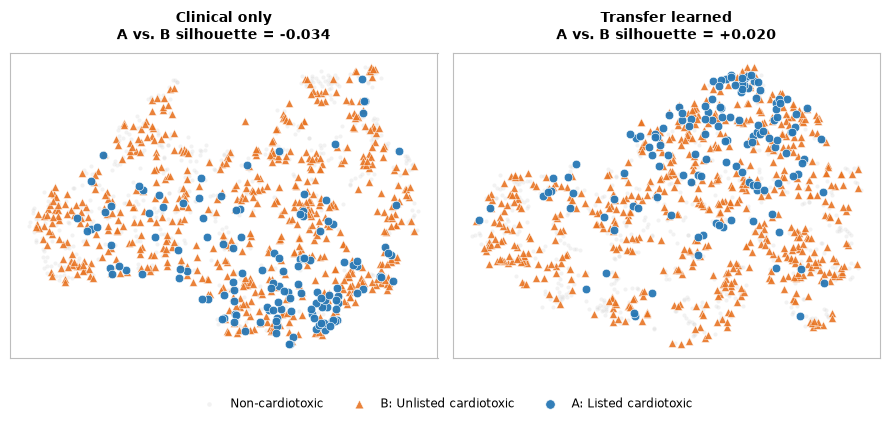

In [17]:

# ── 셀 B │ t-SNE visualization (improved group distinction) ──
import matplotlib.pyplot as plt
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score

L = M['listed'].values.astype(bool)
pos = y.astype(bool)

# Group masks
mask_A = pos & L
mask_B = pos & ~L
mask_NC = ~pos

fig, axes = plt.subplots(1, 2, figsize=(9.0, 4.2))

# High-contrast colors
COLOR_A = '#2878B5'   # Listed: blue
COLOR_B = '#E87524'   # Unlisted: orange
COLOR_NC = '#C7C7C7'  # Non-cardiotoxic: light gray

for ax, name in zip(axes, ['Clinical only', 'Transfer learned']):

    Z = TSNE(
        n_components=2,
        perplexity=30,
        init='pca',
        learning_rate='auto',
        random_state=42
    ).fit_transform(EMB[name])

    # 1. Non-cardiotoxic: background layer
    ax.scatter(
        Z[mask_NC, 0], Z[mask_NC, 1],
        s=9,
        c=COLOR_NC,
        marker='o',
        alpha=0.22,
        linewidths=0,
        rasterized=True,
        label='Non-cardiotoxic',
        zorder=1
    )

    # 2. B: unlisted cardiotoxic
    ax.scatter(
        Z[mask_B, 0], Z[mask_B, 1],
        s=32,
        c=COLOR_B,
        marker='^',
        alpha=0.90,
        edgecolors='white',
        linewidths=0.35,
        rasterized=True,
        label='B: Unlisted cardiotoxic',
        zorder=2
    )

    # 3. A: listed cardiotoxic
    ax.scatter(
        Z[mask_A, 0], Z[mask_A, 1],
        s=38,
        c=COLOR_A,
        marker='o',
        alpha=0.95,
        edgecolors='white',
        linewidths=0.45,
        rasterized=True,
        label='A: Listed cardiotoxic',
        zorder=3
    )

    # Silhouette score in original embedding space (not t-SNE space)
    sil = silhouette_score(
        EMB[name][pos],
        L[pos],
        metric='cosine'
    )

    ax.set_title(
        f'{name}\nA vs. B silhouette = {sil:+.3f}',
        fontsize=10,
        fontweight='bold',
        pad=10
    )

    ax.set_xticks([])
    ax.set_yticks([])

    for spine in ax.spines.values():
        spine.set_color('#BDBDBD')
        spine.set_linewidth(0.8)

# Shared legend
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles, labels,
    loc='lower center',
    ncol=3,
    frameon=False,
    fontsize=8.5,
    bbox_to_anchor=(0.5, -0.015),
    markerscale=1.1
)

fig.tight_layout(rect=[0, 0.10, 1, 1])

fig.savefig(
    RES + 'Fig_tsne_arms_improved.png',
    dpi=600,
    bbox_inches='tight'
)
fig.savefig(
    RES + 'Fig_tsne_arms_improved.pdf',
    bbox_inches='tight'
)

plt.show()
